In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rc
from scipy.integrate import solve_ivp
from scipy import optimize as opt
import scipy.linalg as la

rc({"text.usetex": True,
    'family': 'serif', 'serif': ['Computer Modern']})
plt.rcParams.update({'font.size': 10})

def numerov(k, x, y0, *args,**kwargs):
    '''reševanje DE oblike [d²/dx² + k²(x)] y(x) = 0,
    podana funkcija k(x) naj bo že kvadrirana'''
    h = x[1]-x[0]
    y = np.zeros(len(x)+1)
    y[1] = y0[1] #ZP
    y[0] = y0[0] #ZP?
    for i in range(1,len(x)-1):
        y[i+1] = (2*(1-h**2*5/12*k(x[i], *args,**kwargs))*y[i] - (1-h**2/12*k(x[i-1], *args,**kwargs))*y[i-1]) / (1+h**2/12*k(x[i+1], *args,**kwargs))
    return y[1:]

In [2]:
def lomni(x):
    # if x < 1:
    #     n = 2-0.5*x**2
    # else: #x[i]>=1
    #     n = 1
    return np.where(x < 1, 2-0.5*x**2, 1)

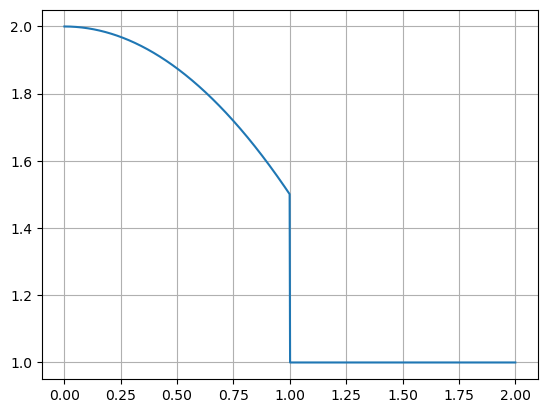

In [3]:
x = np.linspace(0,2,1000)
n = lomni(x)

plt.plot(x,n)
plt.grid()

In [4]:
def k_numerov(x,λ):
    return 1/(4*x**2) + lomni(x)**2*k**2 - λ**2
def DE(x,y,λ):
    R, z = y
    dRdx = z
    dzdx = -k_numerov(x,λ) * R
    return np.array([dRdx,dzdx])

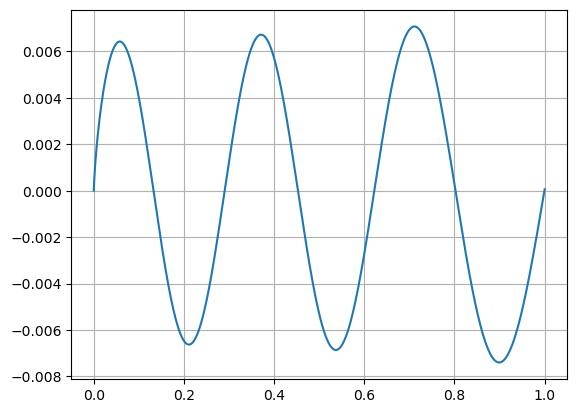

In [5]:
# ročno
k = 10 #prosti parameter (valovno število)
λ = 1 #lastna frekvenca
y0 = 0 #ZP
naklon_0 = 0.5 #ZP
n = 1000
x_min, x_max = 0.0001, 1
dx = (x_max-x_min)/n
x = np.linspace(x_min,x_max,n)
y_zp=np.array([y0,naklon_0])

res = solve_ivp(DE, (x_min,x_max), y0=y_zp, method='RK45', t_eval=x, args=(λ,))
R,dRdx =res.y #R = lastna oblika
x1 =res.t

R_n = numerov(k_numerov, x, y_zp, λ)

plt.plot(x1, R)
#plt.plot(x, R_n)
plt.grid()

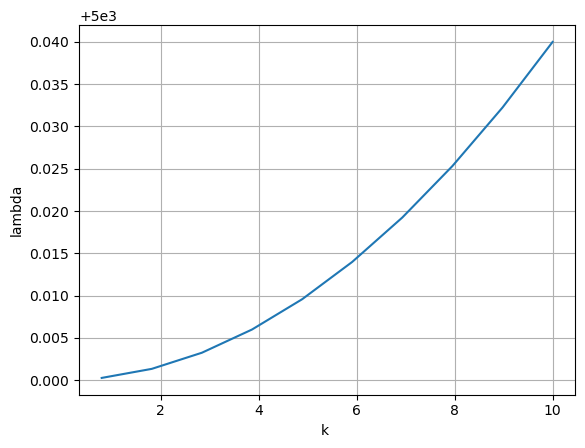

In [6]:
#ni ok
λ = 1  # Initial guess
n = 1000
x_min, x_max = 0.0001, 1
x = np.linspace(x_min, x_max, n)
y_zp = np.array([0, 0.5]) #ZP

k_values = np.linspace(0.8, 10, 10)
eigenvalues = []
for k in k_values:
    res = solve_ivp(DE, (x_min, x_max), y0=y_zp, method='RK45', t_eval=x, args=(λ,))
    R, dRdx = res.y
    lambda_squared = max(k_numerov(x,λ)+ λ**2)
    eigenvalues.append(np.sqrt(lambda_squared))

plt.plot(k_values, eigenvalues)
plt.xlabel('k ')
plt.ylabel('lambda')
plt.grid()

200


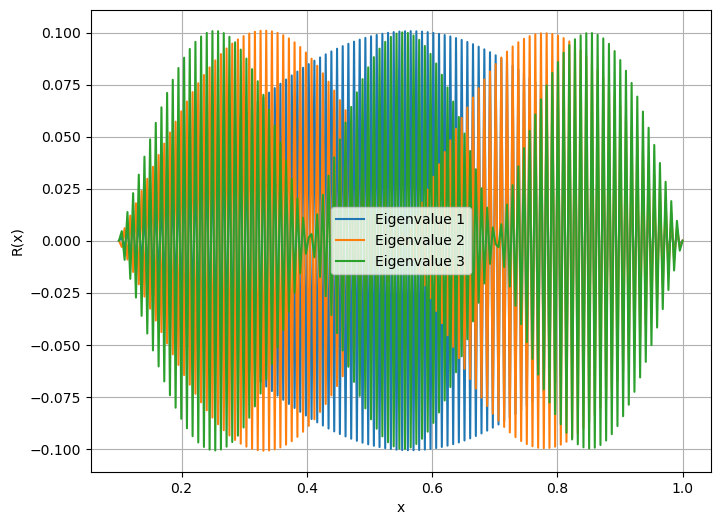

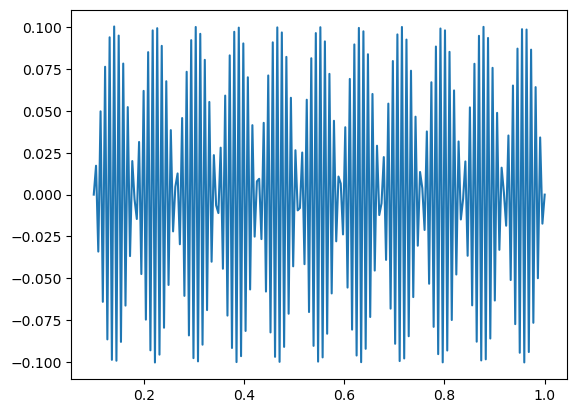

In [7]:
#MKE
def construct_A(x, k, lmbda):
    h = np.diff(x)
    h2 = h**2
    N = len(x)
    A = np.zeros((N, N))
    for i in range(1, N - 1):
        n = lomni(x[i])
        A[i, i-1] = 1 / h2[i-1]
        A[i, i] = -2 / h2[i-1] + 1 / (4 * x[i]**2) + n**2 * k**2 - lmbda**2
        A[i, i+1] = 1 / h2[i]
    A[0, 0] = -2 / h2[0] + 1 / (4 * x[0]**2) + n**2 * k**2 - lmbda**2
    A[-1, -1] = -2 / h2[-1] + 1 / (4 * x[-1]**2) + n**2 * k**2 - lmbda**2
    return A

# Define parameters
N = 200  # Number of grid points
L = 1  # Length of the domain
x = np.linspace(0.1, L, N)  # Spatial grid
k = 1  # Dimensionless wave number
lmbda = 1  # Eigenvalue

# Construct the matrix
A = construct_A(x, k, lmbda)

# Solve the eigenvalue problem
eigenvalues, eigenvectors = la.eig(A)

# Sort the eigenvalues and corresponding eigenvectors
sorted_indices = np.argsort(eigenvalues)
eigenvalues = eigenvalues[sorted_indices]
eigenvectors = eigenvectors[:, sorted_indices]

# Plot the first few eigenfunctions
print(len(eigenvalues))
num_plots = 3
plt.figure(figsize=(8, 6))
for i in range(num_plots):
    plt.plot(x, eigenvectors[:, i], label=f'Eigenvalue {i+1}')
plt.xlabel('x')
plt.ylabel('R(x)')
plt.legend()
plt.grid(True)
plt.show()

i=10
plt.plot(x, eigenvectors[:, i], label=f'Eigenvalue {i+1}')